# 03 — Initial Logistic Regression baseline (development-set evaluation)

**Goal:** train **one** untuned Logistic Regression on the earlier part of the data and measure, honestly, how well it ranks and classifies customers in the **next** period (the development rows).

**Rules this notebook follows**
- **Features:** the 10 conservative features only (7 customer attributes, `pdays`, `previous`, `poutcome`). `duration`, the current-contact features and the economic indicators are excluded (see `DECISIONS.md`).
- **Split:** 60/20/20 in original row order. Fit on **train** only; evaluate on **development** only. The reserved **stream** rows are never inspected, scored or used here.
- **Positive class:** subscription = yes.
- **No** class weighting, hyperparameter tuning, threshold optimisation or model comparison. Whatever the numbers are, they are reported as they are.
- **Threshold:** 0.5 for precision, recall, F1 and the confusion matrix. It is a documented starting point, not a tuned or final choice. PR-AUC and ROC-AUC do not depend on it.
- **Primary metric:** PR-AUC, always read against the random-ranking reference (the positive rate of the rows being evaluated).

In [1]:
import sys; sys.path.insert(0, '..')      # project root, so that `src` can be imported (approved approach)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.pipeline import Pipeline

from src.data import chronological_split, encode_target, load_dataset
from src.features import build_preprocessor, select_baseline_features
from src.metrics import evaluate_binary
from src.settings import BASELINE_FEATURES, DECISION_THRESHOLD, LOGREG_MAX_ITER, SEED

## 1. Data and chronological split

In [2]:
df = load_dataset()
train, dev_rows, _reserved_stream = chronological_split(df)
del _reserved_stream          # the reserved future stream is never inspected, scored or used in this notebook

X_train, y_train = select_baseline_features(train), encode_target(train)
X_dev, y_dev = select_baseline_features(dev_rows), encode_target(dev_rows)

print('Features used (%d):' % len(BASELINE_FEATURES), BASELINE_FEATURES)
split_table = pd.DataFrame({
    'rows': [len(y_train), len(y_dev)],
    'row index range': ['%d to %d' % (X_train.index[0], X_train.index[-1]), '%d to %d' % (X_dev.index[0], X_dev.index[-1])],
    'yes (positive)': [int(y_train.sum()), int(y_dev.sum())],
    'positive rate': ['%.2f%%' % (100 * y_train.mean()), '%.2f%%' % (100 * y_dev.mean())],
}, index=['train', 'development'])
split_table

Features used (10): ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'pdays', 'previous', 'poutcome']


,rows,row index range,yes (positive),positive rate
train,24712,0 to 24711,1188,4.81%
development,8238,24712 to 32949,912,11.07%


## 2. One untuned model, fitted on training rows only

A single scikit-learn `Pipeline`: preprocessing (median-impute `pdays_days`, scale `age`, one-hot encode the categoricals, with `"unknown"` as its own category) followed by `LogisticRegression` with library defaults (L2 penalty, `C = 1.0`, no class weights). `max_iter` is raised to 1000 only so that the solver can finish. `fit` is called on training rows and nothing else, so every statistic and coefficient comes from them.

In [3]:
model = Pipeline([
    ('preprocess', build_preprocessor()),
    ('logreg', LogisticRegression(max_iter=LOGREG_MAX_ITER, random_state=SEED)),
])
model.fit(X_train, y_train)
print('Fitted on', len(X_train), 'training rows. Converged in', int(model.named_steps['logreg'].n_iter_[0]), 'iterations.')

Fitted on 24712 training rows. Converged in 38 iterations.


## 3. Development-set results (threshold 0.5)

In [4]:
dev_scores = model.predict_proba(X_dev)[:, 1]          # predicted probability of "yes"
m = evaluate_binary(y_dev, dev_scores, threshold=DECISION_THRESHOLD)

results = pd.DataFrame([
    ('Development positive rate (prevalence)',            '%.4f' % m['prevalence'],  'share of development rows that are "yes"'),
    ('PR-AUC (model)  [primary metric]',                  '%.4f' % m['pr_auc'],      'area under the precision-recall curve'),
    ('PR-AUC of random ranking (reference)',              '%.4f' % m['random_pr_auc'], 'equals the development positive rate'),
    ('ROC-AUC',                                           '%.4f' % m['roc_auc'],     '0.5 = random ranking'),
    ('Precision @ %.1f' % m['threshold'],                 '%.4f' % m['precision'],   'of rows predicted yes, share that are yes'),
    ('Recall @ %.1f' % m['threshold'],                    '%.4f' % m['recall'],      'of real yes rows, share found'),
    ('F1 @ %.1f' % m['threshold'],                        '%.4f' % m['f1'],          'balance of precision and recall'),
    ('Predicted positive @ %.1f' % m['threshold'],         '%d of %d (%.2f%%)' % (m['n_predicted_positive'], m['n_rows'], 100 * m['pct_predicted_positive']), 'rows with probability >= threshold'),
], columns=['metric', 'value', 'meaning']).set_index('metric')
results

,value,meaning
metric,,
Development positive rate (prevalence),0.1107,"share of development rows that are ""yes"""
PR-AUC (model) [primary metric],0.1726,area under the precision-recall curve
PR-AUC of random ranking (reference),0.1107,equals the development positive rate
ROC-AUC,0.5819,0.5 = random ranking
Precision @ 0.5,0.0000,"of rows predicted yes, share that are yes"
Recall @ 0.5,0.0000,"of real yes rows, share found"
F1 @ 0.5,0.0000,balance of precision and recall
Predicted positive @ 0.5,0 of 8238 (0.00%),rows with probability >= threshold


### Confusion matrix (development rows, threshold 0.5)
Rows are what really happened, columns are what the model predicted. **Positive class = subscribed ("yes").**

,Predicted: no,Predicted: yes
Actual: no,7326,0
Actual: yes,912,0


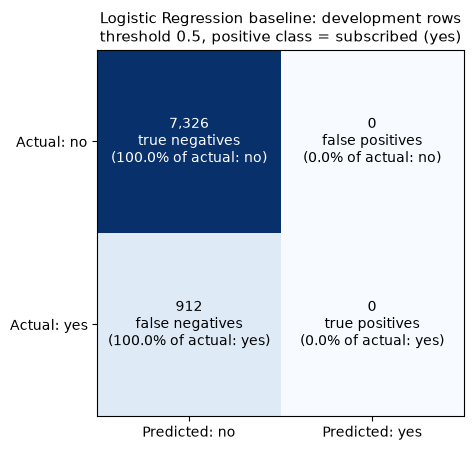

In [5]:
cm = pd.DataFrame([[m['tn'], m['fp']], [m['fn'], m['tp']]],
                  index=['Actual: no', 'Actual: yes'], columns=['Predicted: no', 'Predicted: yes'])
display(cm)

fig, ax = plt.subplots(figsize=(6.4, 4.6))
ax.imshow(cm.values, cmap='Blues')
row_totals = cm.sum(axis=1).values
labels = [['true negatives', 'false positives'], ['false negatives', 'true positives']]
for i in range(2):
    for j in range(2):
        value = cm.values[i, j]
        ax.text(j, i, f'{value:,}\n{labels[i][j]}\n({100 * value / row_totals[i]:.1f}% of {cm.index[i].lower()})',
                ha='center', va='center', fontsize=10, color='white' if value > cm.values.max() / 2 else 'black')
ax.set_xticks([0, 1], cm.columns); ax.set_yticks([0, 1], cm.index); ax.grid(False)
ax.set_title(f'Logistic Regression baseline: development rows\nthreshold {m["threshold"]:.1f}, positive class = subscribed (yes)', fontsize=11)
fig.tight_layout(); fig.savefig('../figures/07_baseline_confusion_matrix.png', dpi=200); plt.show()

## 4. Cross-check: every reported number against scikit-learn and by hand
`evaluate_binary` is checked against direct scikit-learn calls and, for the threshold metrics, against formulas computed from the confusion counts.

In [6]:
pred = (dev_scores >= DECISION_THRESHOLD).astype(int)
tn, fp, fn, tp = confusion_matrix(y_dev, pred, labels=[0, 1]).ravel()
precision_by_hand = tp / (tp + fp) if (tp + fp) else 0.0
recall_by_hand = tp / (tp + fn)
f1_denominator = precision_by_hand + recall_by_hand
f1_by_hand = 2 * precision_by_hand * recall_by_hand / f1_denominator if f1_denominator else 0.0   # F1 is 0 when precision and recall are both 0
decision = model.decision_function(X_dev)

checks = [
    ('prevalence',              m['prevalence'],              y_dev.mean()),
    ('random-ranking PR-AUC',   m['random_pr_auc'],           y_dev.sum() / len(y_dev)),
    ('PR-AUC',                  m['pr_auc'],                  average_precision_score(y_dev, dev_scores)),
    ('ROC-AUC',                 m['roc_auc'],                 roc_auc_score(y_dev, dev_scores)),
    ('precision (sklearn)',     m['precision'],               precision_score(y_dev, pred, zero_division=0)),
    ('precision (tp/(tp+fp))',  m['precision'],               precision_by_hand),
    ('recall (sklearn)',        m['recall'],                  recall_score(y_dev, pred, zero_division=0)),
    ('recall (tp/(tp+fn))',     m['recall'],                  recall_by_hand),
    ('F1 (sklearn)',            m['f1'],                      f1_score(y_dev, pred, zero_division=0)),
    ('F1 (2PR/(P+R))',          m['f1'],                      f1_by_hand),
    ('n predicted positive',    m['n_predicted_positive'],    int((dev_scores >= DECISION_THRESHOLD).sum())),
    ('% predicted positive',    m['pct_predicted_positive'],  pred.mean()),
    ('tn / fp / fn / tp',       (m['tn'], m['fp'], m['fn'], m['tp']), (tn, fp, fn, tp)),
    ('probability = sigmoid(decision function)', float(dev_scores.mean()), float((1 / (1 + np.exp(-decision))).mean())),
]
rows = []
for name, reported, check in checks:
    ok = bool(np.allclose(reported, check, rtol=0, atol=1e-12))
    rows.append((name, reported if isinstance(reported, tuple) else round(float(reported), 6),
                 check if isinstance(check, tuple) else round(float(check), 6), 'OK' if ok else 'MISMATCH'))
    assert ok, name
pd.DataFrame(rows, columns=['quantity', 'reported by evaluate_binary', 'independent check', 'status']).set_index('quantity')

,reported by evaluate_binary,independent check,status
quantity,,,
prevalence,0.110706,0.110706,OK
random-ranking PR-AUC,0.110706,0.110706,OK
PR-AUC,0.172592,0.172592,OK
ROC-AUC,0.581872,0.581872,OK
precision (sklearn),0.0,0.0,OK
precision (tp/(tp+fp)),0.0,0.0,OK
recall (sklearn),0.0,0.0,OK
recall (tp/(tp+fn)),0.0,0.0,OK
F1 (sklearn),0.0,0.0,OK


## 5. In-sample sanity check (training rows) — NOT evidence of generalisation
This only shows the pipeline learned something from the rows it was fitted on. Performance on rows a model has already seen says nothing about how it will do on new data.

In [7]:
train_scores = model.predict_proba(X_train)[:, 1]
tm = evaluate_binary(y_train, train_scores, threshold=DECISION_THRESHOLD)
print('Training rows (in-sample): PR-AUC %.4f | random-ranking reference %.4f | ROC-AUC %.4f' % (tm['pr_auc'], tm['random_pr_auc'], tm['roc_auc']))
print('Development rows (out-of-sample): PR-AUC %.4f | random-ranking reference %.4f | ROC-AUC %.4f' % (m['pr_auc'], m['random_pr_auc'], m['roc_auc']))

Training rows (in-sample): PR-AUC 0.0577 | random-ranking reference 0.0481 | ROC-AUC 0.5534
Development rows (out-of-sample): PR-AUC 0.1726 | random-ranking reference 0.1107 | ROC-AUC 0.5819


## 6. Diagnostics (descriptive only; no settings are changed)
Context for reading the numbers above: how the predicted probabilities compare with the real positive rates, and what the model leaned on.

In [8]:
diag = pd.DataFrame({
    'positive rate (actual)':            [y_train.mean(), y_dev.mean()],
    'mean predicted probability':        [train_scores.mean(), dev_scores.mean()],
    'highest predicted probability':     [train_scores.max(), dev_scores.max()],
    'share predicted yes @ threshold':   [(train_scores >= DECISION_THRESHOLD).mean(), (dev_scores >= DECISION_THRESHOLD).mean()],
}, index=['train', 'development']).round(4)
display(diag)
print('PR-AUC lift over random ranking on development rows: %.2fx' % (m['pr_auc'] / m['random_pr_auc']))

names = model.named_steps['preprocess'].named_steps['columns'].get_feature_names_out()
coefs = pd.Series(model.named_steps['logreg'].coef_[0], index=names)
print('\nLargest coefficients by absolute size (association in this fitted model, not a causal effect):')
coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(8).round(3).to_frame('coefficient')

,positive rate (actual),mean predicted probability,highest predicted probability,share predicted yes @ threshold
train,0.0481,0.0481,0.1227,0.0
development,0.1107,0.0496,0.4247,0.0


PR-AUC lift over random ranking on development rows: 1.56x

Largest coefficients by absolute size (association in this fitted model, not a causal effect):


,coefficient
imputed__pdays_days,-0.522
categorical__job_housemaid,-0.521
categorical__marital_unknown,0.439
categorical__job_unemployed,-0.346
categorical__job_student,0.338
categorical__job_retired,0.326
passthrough__pdays_is_999,-0.287
categorical__marital_divorced,-0.234


## 7. Investigation: why is the baseline weak? (descriptive only; nothing is changed or re-tuned)
Two things stand out above: the model ranks the development rows only a little better than random, and **no development row reaches the 0.5 threshold**. The tables below look for context. They use the training labels, and the development *features* (never the development labels), to compare what the model was able to learn from with what it later faces.

In [9]:
history = pd.DataFrame({
    'train: share of rows':       train.poutcome.value_counts(normalize=True),
    'train: number of rows':      train.poutcome.value_counts(),
    'train: yes rate':            y_train.groupby(train.poutcome).mean(),
    'development: share of rows': dev_rows.poutcome.value_counts(normalize=True),   # features only
}).round(4)
history.index.name = 'poutcome (outcome of the previous campaign)'
display(history)
print(f"previous > 0:  {100 * (train.previous > 0).mean():.2f}% of training rows ({int((train.previous > 0).sum())}) "
      f"vs {100 * (dev_rows.previous > 0).mean():.2f}% of development rows ({int((dev_rows.previous > 0).sum())})")
print(f"Real pdays value (not 999):  {int((train.pdays != 999).sum())} training rows vs {int((dev_rows.pdays != 999).sum())} development rows")
print(f"In-sample (training) ROC-AUC is only {tm['roc_auc']:.3f}: even on the rows it was fitted on, the 10 features separate yes from no weakly.")
print(f"Highest predicted probability: {train_scores.max():.3f} on training rows, {dev_scores.max():.3f} on development rows (threshold {DECISION_THRESHOLD}).")

,train: share of rows,train: number of rows,train: yes rate,development: share of rows
poutcome (outcome of the previous campaign),,,,
failure,0.0050,124,0.0403,0.2407
nonexistent,0.9947,24582,0.0481,0.7396
success,0.0002,6,0.1667,0.0197


previous > 0:  0.53% of training rows (130) vs 26.04% of development rows (2145)
Real pdays value (not 999):  6 training rows vs 168 development rows
In-sample (training) ROC-AUC is only 0.553: even on the rows it was fitted on, the 10 features separate yes from no weakly.
Highest predicted probability: 0.123 on training rows, 0.425 on development rows (threshold 0.5).


**How to read this (hypotheses, not proven causes):**
1. **The history features barely vary in the training rows.** Almost every training row has no earlier campaign, so the model has very little to learn from `pdays`, `previous` and `poutcome`; its `pdays_days` coefficient rests on only 6 real values. Among later (development) rows far more customers were contacted before.
2. **The remaining customer attributes are weak signals.** The in-sample ROC-AUC shows the model separates yes from no only slightly even where it was fitted.
3. **Base-rate shift.** The model learns the low training positive rate, so its probabilities stay low; on development rows with a higher positive rate none reaches 0.5. The zero precision, recall and F1 therefore come from the fixed threshold, not from a bug (the cross-check in section 4 passes). The ranking metrics (PR-AUC, ROC-AUC) do not depend on the threshold.
4. **What was deliberately not done:** no feature was added, no threshold lowered, no class weights set, no hyperparameters tuned. Any such change would need an explicit decision and must be judged without peeking at the stream.

## 7. Results summary (generated from the computed values above)

In [10]:
print(f'''Initial Logistic Regression baseline (untuned; 10 conservative features; trained on {len(y_train):,} earliest rows).
Evaluated on the next {len(y_dev):,} rows (development). The reserved stream rows were not used.

- Positive rate in development rows: {100 * m['prevalence']:.2f}%  (random-ranking PR-AUC reference: {m['random_pr_auc']:.4f})
- PR-AUC {m['pr_auc']:.4f} ({m['pr_auc'] / m['random_pr_auc']:.2f}x the random reference)   ROC-AUC {m['roc_auc']:.4f}
- At threshold {m['threshold']:.1f}: precision {m['precision']:.3f}, recall {m['recall']:.3f}, F1 {m['f1']:.3f}
- Predicted yes: {m['n_predicted_positive']:,} of {m['n_rows']:,} rows ({100 * m['pct_predicted_positive']:.2f}%); real yes: {m['n_positive']:,}
- Highest predicted probability on development rows: {dev_scores.max():.3f} (threshold {m['threshold']:.1f})
- Confusion matrix: TN {m['tn']:,}  FP {m['fp']:,}  FN {m['fn']:,}  TP {m['tp']:,}

Caveats: one split, one untuned model, one fixed 0.5 threshold. These are development-set results, not final performance,
and they say nothing yet about retraining strategies. The training positive rate ({100 * y_train.mean():.2f}%) differs from the
development positive rate ({100 * y_dev.mean():.2f}%), which affects threshold-based metrics even if the ranking were unchanged.''')

Initial Logistic Regression baseline (untuned; 10 conservative features; trained on 24,712 earliest rows).
Evaluated on the next 8,238 rows (development). The reserved stream rows were not used.

- Positive rate in development rows: 11.07%  (random-ranking PR-AUC reference: 0.1107)
- PR-AUC 0.1726 (1.56x the random reference)   ROC-AUC 0.5819
- At threshold 0.5: precision 0.000, recall 0.000, F1 0.000
- Predicted yes: 0 of 8,238 rows (0.00%); real yes: 912
- Highest predicted probability on development rows: 0.425 (threshold 0.5)
- Confusion matrix: TN 7,326  FP 0  FN 912  TP 0

Caveats: one split, one untuned model, one fixed 0.5 threshold. These are development-set results, not final performance,
and they say nothing yet about retraining strategies. The training positive rate (4.81%) differs from the
development positive rate (11.07%), which affects threshold-based metrics even if the ranking were unchanged.
